In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load Data

In [2]:
train_data_df = pd.read_csv("../data/train.csv")
test_data_df = pd.read_csv("../data/test.csv")

In [3]:
train_data_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
test_data_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


# Basic EDA

In [5]:
print(train_data_df.shape)
print(train_data_df.info())
print(train_data_df.describe())

(1460, 81)
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallC

Check where there are null values

In [6]:
train_data_df.isnull().sum().sort_values(ascending=False).head(20)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Id                 0
dtype: int64

# Question 1 EDA

In [7]:
df = train_data_df.copy()
df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
df['TotalBath'] = df['FullBath'] + 0.5*df['HalfBath'] + df['BsmtFullBath'] + 0.5*df['BsmtHalfBath']
df['HouseAgeAtSale'] = df['YrSold'] - df['YearBuilt']

# NaN in these text columns means "feature absent"
txt = df.select_dtypes(exclude=['number', 'category']).columns
df[txt] = df[txt].fillna('None')

df['QualTier'] = pd.cut(df['OverallQual'], [0,4,6,8,10],
                        labels=['Low (1-4)','Average (5-6)','Good (7-8)','Excellent (9-10)'])
df['SizeTier'] = pd.qcut(df['TotalSF'], 3, labels=['Small','Medium','Large'])

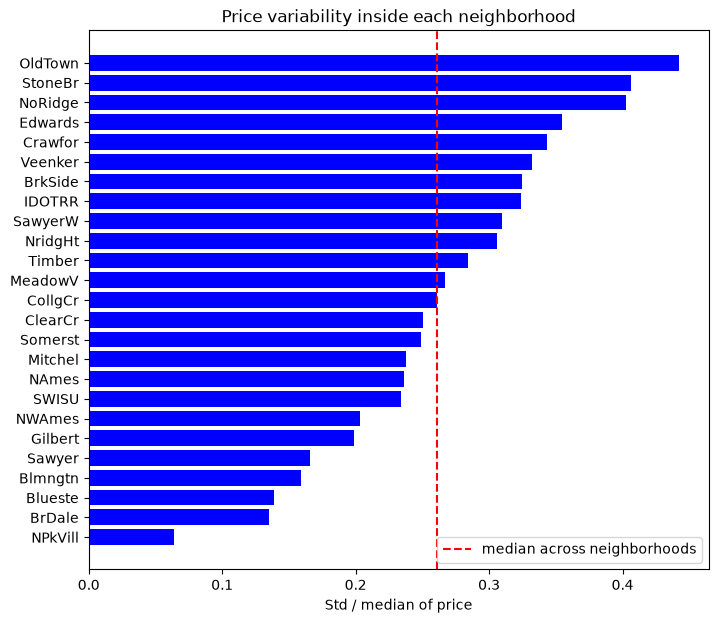

In [8]:
nb = df.groupby('Neighborhood')['SalePrice'].agg(['median','std','count'])
nb['CV'] = nb['std'] / nb['median']
nb = nb.sort_values('CV')

plt.figure(figsize=(8,7))
plt.barh(nb.index, nb['CV'], color='blue')
plt.axvline(nb['CV'].median(), color='red', ls='--', label='median across neighborhoods')
plt.xlabel('Std / median of price'); plt.legend()
plt.title('Price variability inside each neighborhood')
plt.show()

Long bar means homes in that neighborhood have widely different prices, so one neighborhood median describes them poorly.
Helps answer Q1: these are the neighborhoods where neighborhood-level estimates are least reliable and property-level review matters most. Short bars show where a neighborhood estimate is adequate.

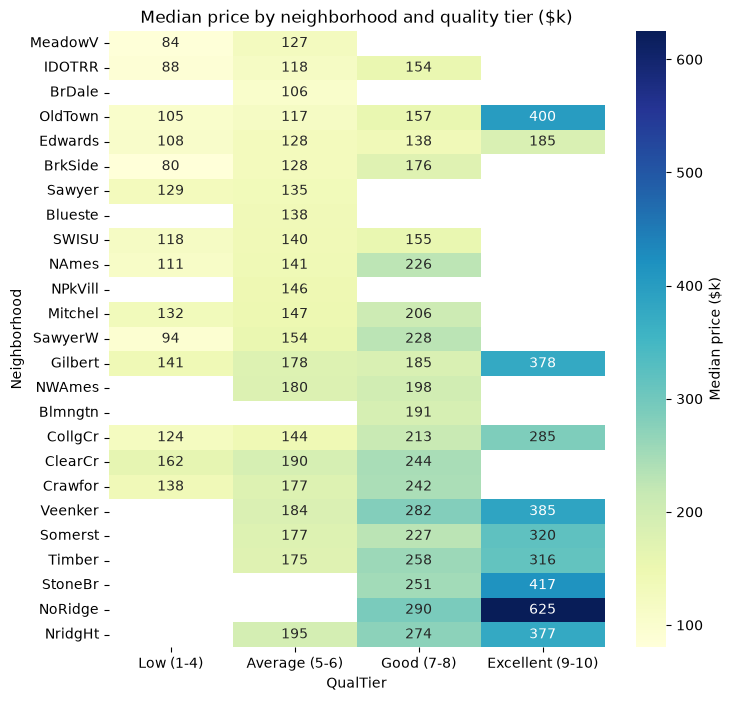

In [9]:
pt = df.pivot_table(index='Neighborhood', columns='QualTier',
                    values='SalePrice', aggfunc='median', observed=True)
pt = pt.loc[df.groupby('Neighborhood')['SalePrice'].median().sort_values().index]
plt.figure(figsize=(8,8))
sns.heatmap(pt / 1000, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'Median price ($k)'})
plt.title('Median price by neighborhood and quality tier ($k)')
plt.show()

read each row left to right. That’s one neighborhood, with quality rising. Blank cells mean no homes of that type exist there.
Helps answer Q1: if prices climb steeply across a single row, quality moves price substantially even when location is held fixed.
A neighborhood median hides that entirely.

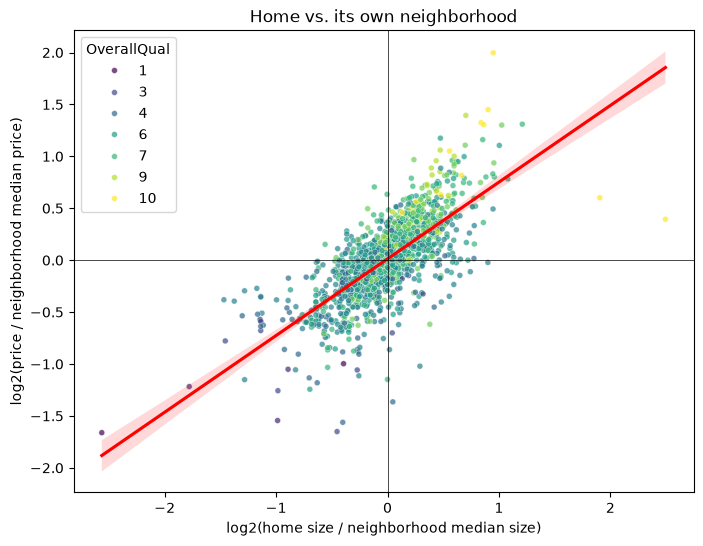

Correlation: 0.72


In [10]:
df['RelPrice'] = df['SalePrice'] / df.groupby('Neighborhood')['SalePrice'].transform('median')
df['RelSF'] = df['TotalSF'] / df.groupby('Neighborhood')['TotalSF'].transform('median')

plt.figure(figsize=(8,6))
sns.scatterplot(x=np.log2(df['RelSF']), y=np.log2(df['RelPrice']),
                hue=df['OverallQual'], palette='viridis', s=18, alpha=0.7)
sns.regplot(x=np.log2(df['RelSF']), y=np.log2(df['RelPrice']), scatter=False, color='red')
plt.axhline(0, color='k', lw=0.5); plt.axvline(0, color='k', lw=0.5)
plt.xlabel('log2(home size / neighborhood median size)')
plt.ylabel('log2(price / neighborhood median price)')
plt.title('Home vs. its own neighborhood')
plt.show()
print('Correlation:', round(np.log2(df['RelSF']).corr(np.log2(df['RelPrice'])), 2))

each point is a home measured against its own neighborhood. 0 means exactly typical. The upward slope plus the color gradient show that larger and higher-quality homes sit above their neighborhood price.
Helps answer Q1: this strips location out completely. The remaining pattern is what property characteristics add on top of neighborhood. It helps assessors flag homes whose price departs from what their size and quality imply.

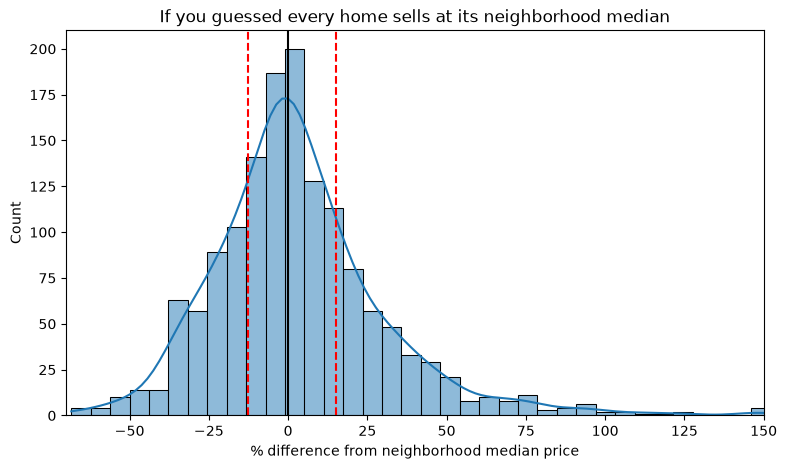

Typical miss (median absolute % error): 14.1 %
Share of homes missed by more than 20%: 36.3 %


In [11]:
nb_med = df.groupby('Neighborhood')['SalePrice'].transform('median')
df['NbPctErr'] = (df['SalePrice'] - nb_med) / nb_med * 100   # % above/below neighborhood median

plt.figure(figsize=(9,5))
sns.histplot(df['NbPctErr'], bins=60, kde=True)
plt.axvline(0, color='k')
for p in [25, 75]:
    plt.axvline(df['NbPctErr'].quantile(p/100), color='red', ls='--')
plt.xlabel('% difference from neighborhood median price'); plt.xlim(-70, 150)
plt.title('If you guessed every home sells at its neighborhood median')
plt.show()
print('Typical miss (median absolute % error):', round(df['NbPctErr'].abs().median(), 1), '%')
print('Share of homes missed by more than 20%:', round((df['NbPctErr'].abs() > 20).mean()*100, 1), '%')

the distribution of how far each home’s actual price is from its neighborhood median, as a percent. Red dashed lines mark the middle 50% of homes.
Helps answer Q1: this is the baseline error of neighborhood-level estimates. A wide spread means that estimate often misses by a lot, which is the room property characteristics have to improve on. The printed numbers give you a headline figure for the write-up.

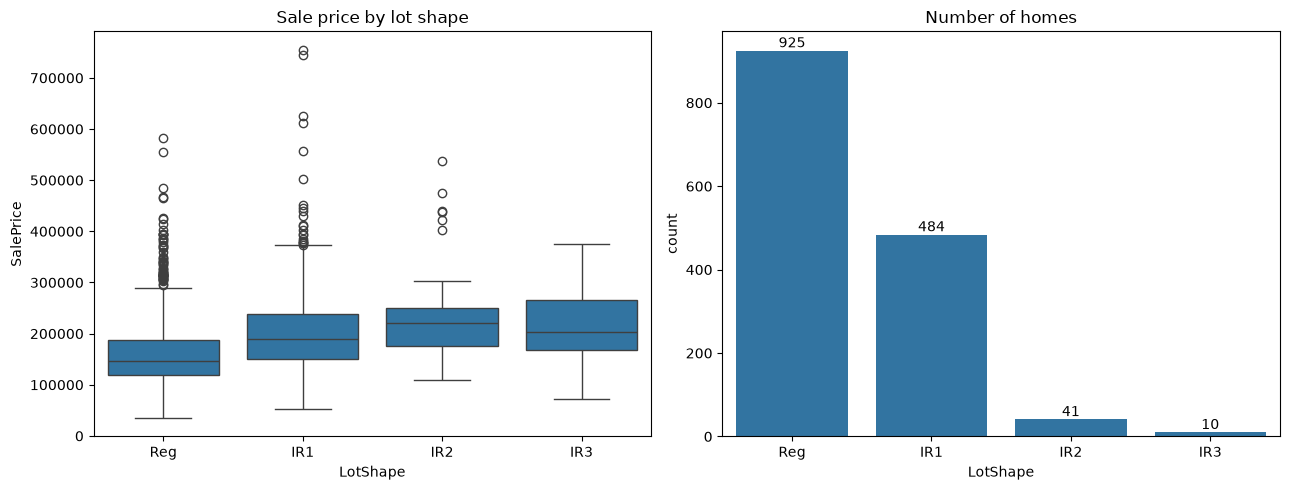

In [12]:
order = ['Reg', 'IR1', 'IR2', 'IR3']
fig, axes = plt.subplots(1, 2, figsize=(13,5))
sns.boxplot(data=df, x='LotShape', y='SalePrice', order=order, ax=axes[0])
axes[0].set_title('Sale price by lot shape')
sns.countplot(data=df, x='LotShape', order=order, ax=axes[1])
axes[1].set_title('Number of homes')
for p in axes[1].patches:
    axes[1].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.tight_layout(); plt.show()

the price distribution for each shape.how many homes are in each.
Helps answer Q1: the raw gap between regular and irregular lots. The count panel tells you how much to trust each box. IR3 is tiny, so ignore its pattern.

the price distribution for each shape.how many homes are in each.
Helps answer Q1: the raw gap between regular and irregular lots. The count panel tells you how much to trust each box. IR3 is tiny, so ignore its pattern.

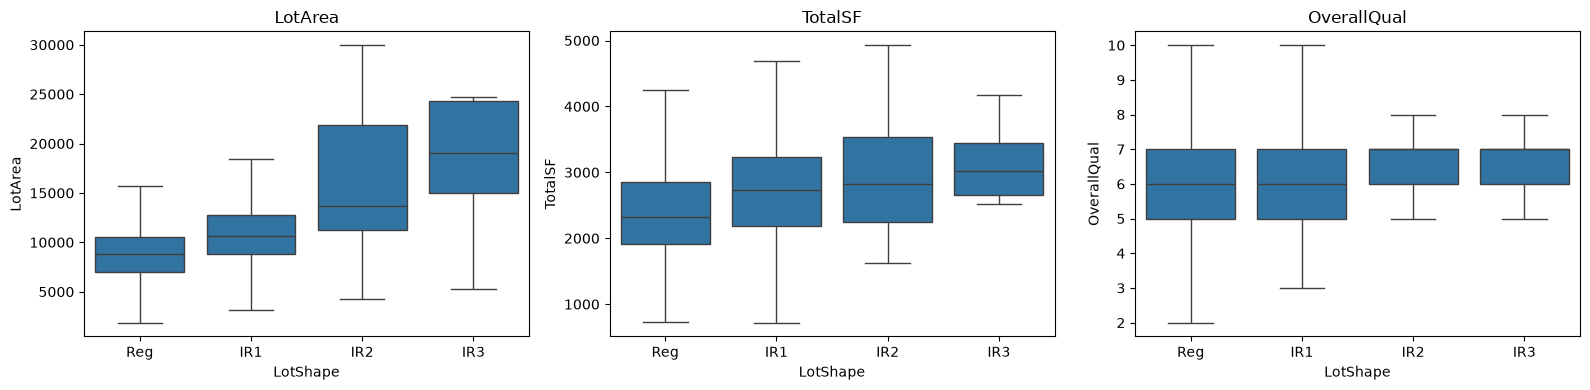

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, c in zip(axes, ['LotArea', 'TotalSF', 'OverallQual']):
    sns.boxplot(data=df, x='LotShape', y=c, order=order, showfliers=False, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

lot size, house size and quality by lot shape.
Helps: if irregular lots are higher on these, the price gap is likely explained by size and quality instead of by the shape.

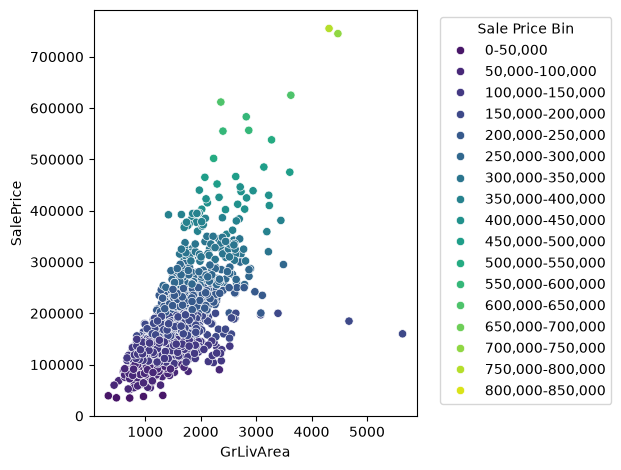

In [ ]:
# make bin labels for housing prices every $50,000
sale_price_bins = [
    f'{i:,}-{i+50_000:,}'
    for i in range(0, 850_000, 50_000)
]

# create new column and map price to correct bin
train_data_df['SalePriceBin'] = pd.cut(
    train_data_df['SalePrice'],
    bins=list(range(0, 850001, 50000)),
    labels=sale_price_bins,
    include_lowest=True
)

# plot the living area comapred to price and use the pricing bins as hue
sns.scatterplot(
    data=train_data_df,
    x='GrLivArea',
    y='SalePrice',
    hue='SalePriceBin',
    palette='viridis'
)

plt.legend(title='Sale Price Bin', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

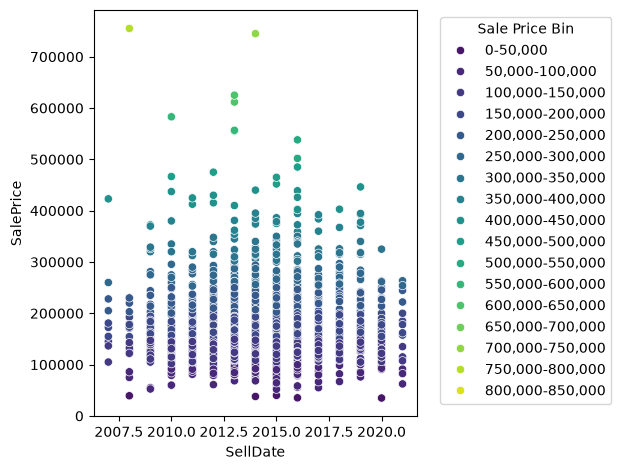

In [ ]:
train_data_df['SellDate'] = train_data_df['MoSold'] + train_data_df['YrSold']

# plot the sell date comapred to price and use the pricing bins as hue
sns.scatterplot(
    data=train_data_df,
    x='SellDate',
    y='SalePrice',
    hue='SalePriceBin',
    palette='viridis'
)

plt.legend(title='Sale Price Bin', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

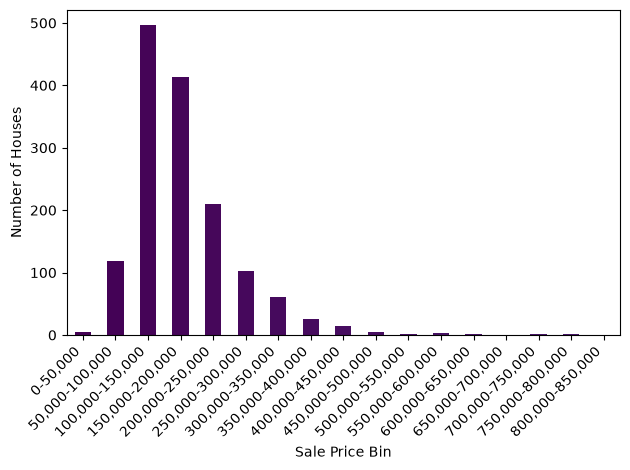

In [ ]:
train_data_df['SalePriceBin'].value_counts(sort=False).plot(kind='bar', color=plt.cm.viridis(
    range(len(sale_price_bins))
))
plt.xticks(rotation=45, ha='right')
plt.xlabel('Sale Price Bin')
plt.ylabel('Number of Houses')
plt.tight_layout()
plt.show()

Most houses fell within 100,000 and 250,000.

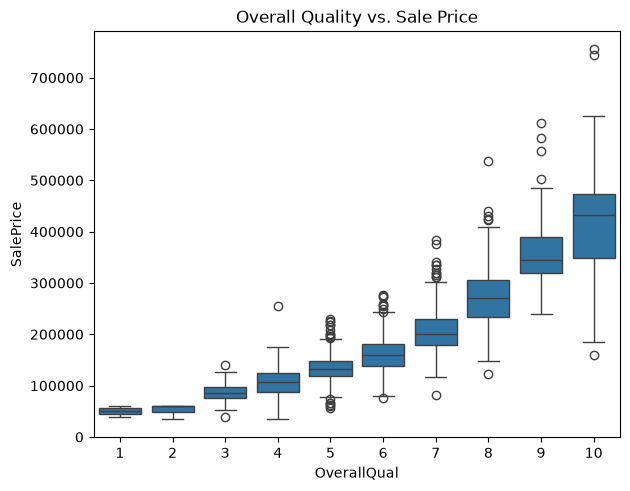

In [ ]:


sns.boxplot(data=train_data_df, x='OverallQual', y='SalePrice')

plt.tight_layout()
plt.title("Overall Quality vs. Sale Price")
plt.show()

## Compare Sale Prices Across Categories

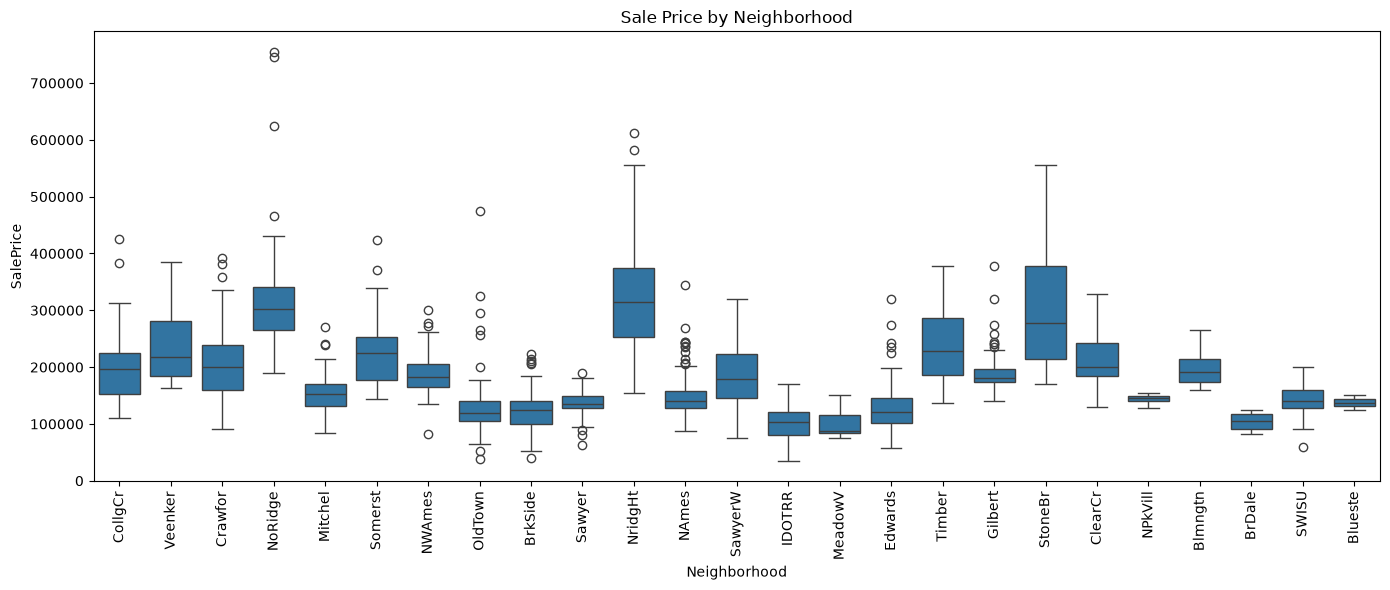

In [ ]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=train_data_df, x='Neighborhood', y='SalePrice')
plt.xticks(rotation=90)
plt.title('Sale Price by Neighborhood')
plt.tight_layout()
plt.show()

# Question 2 EDA

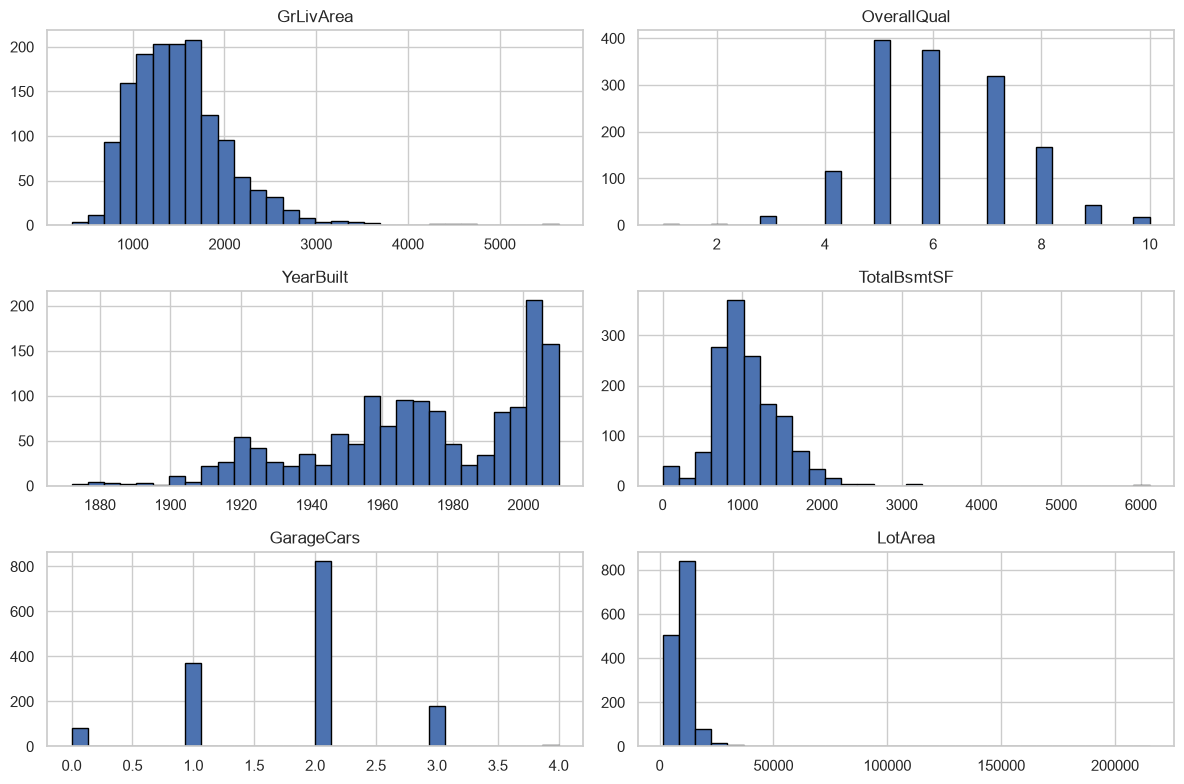

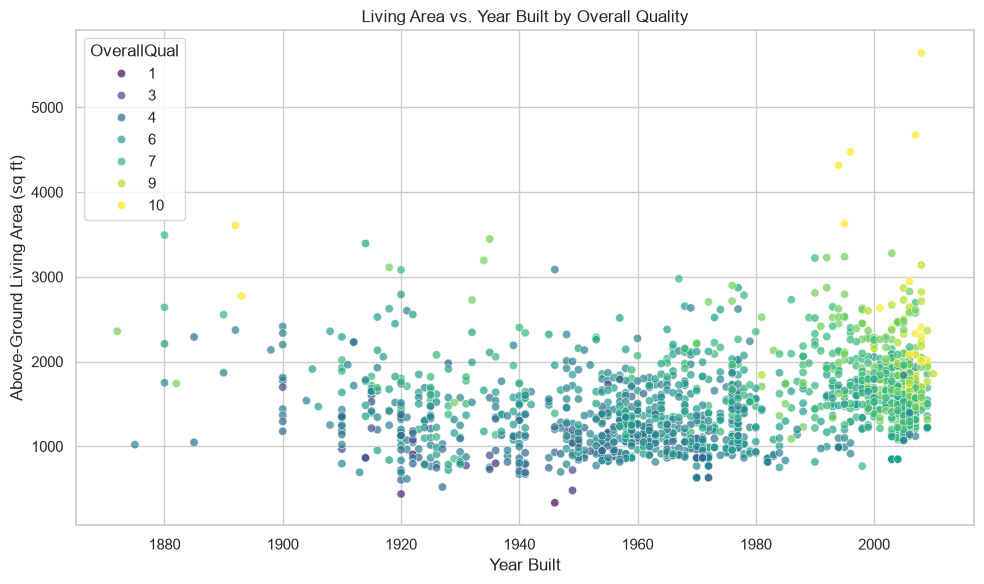

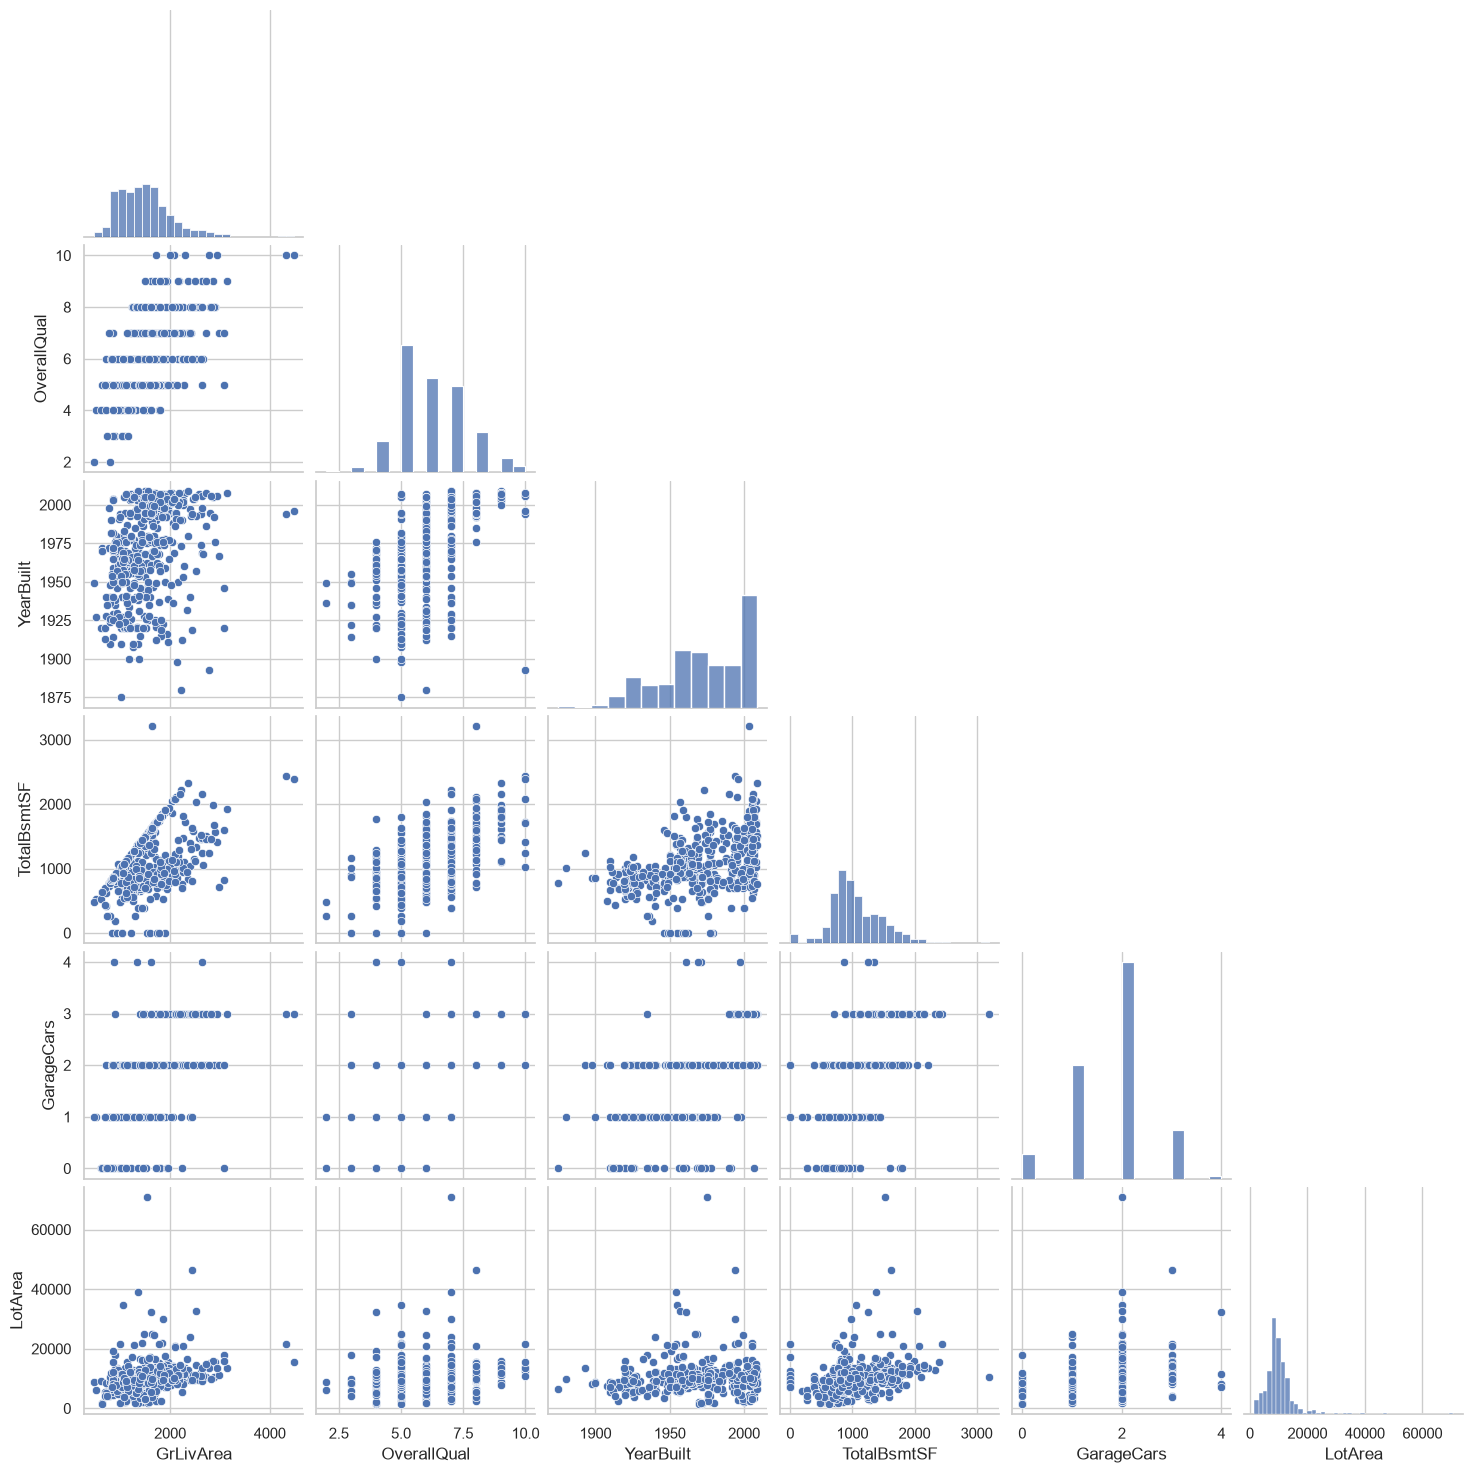

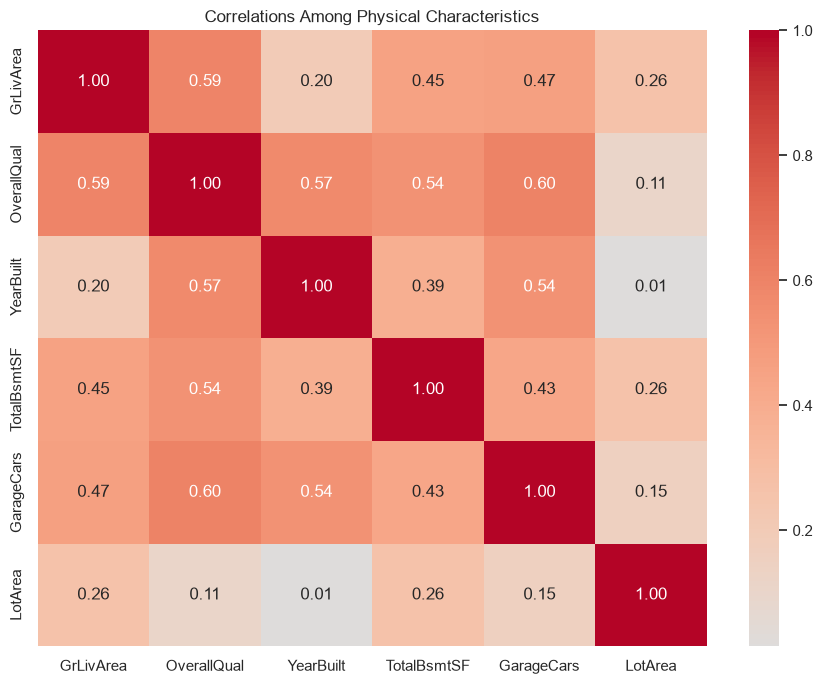

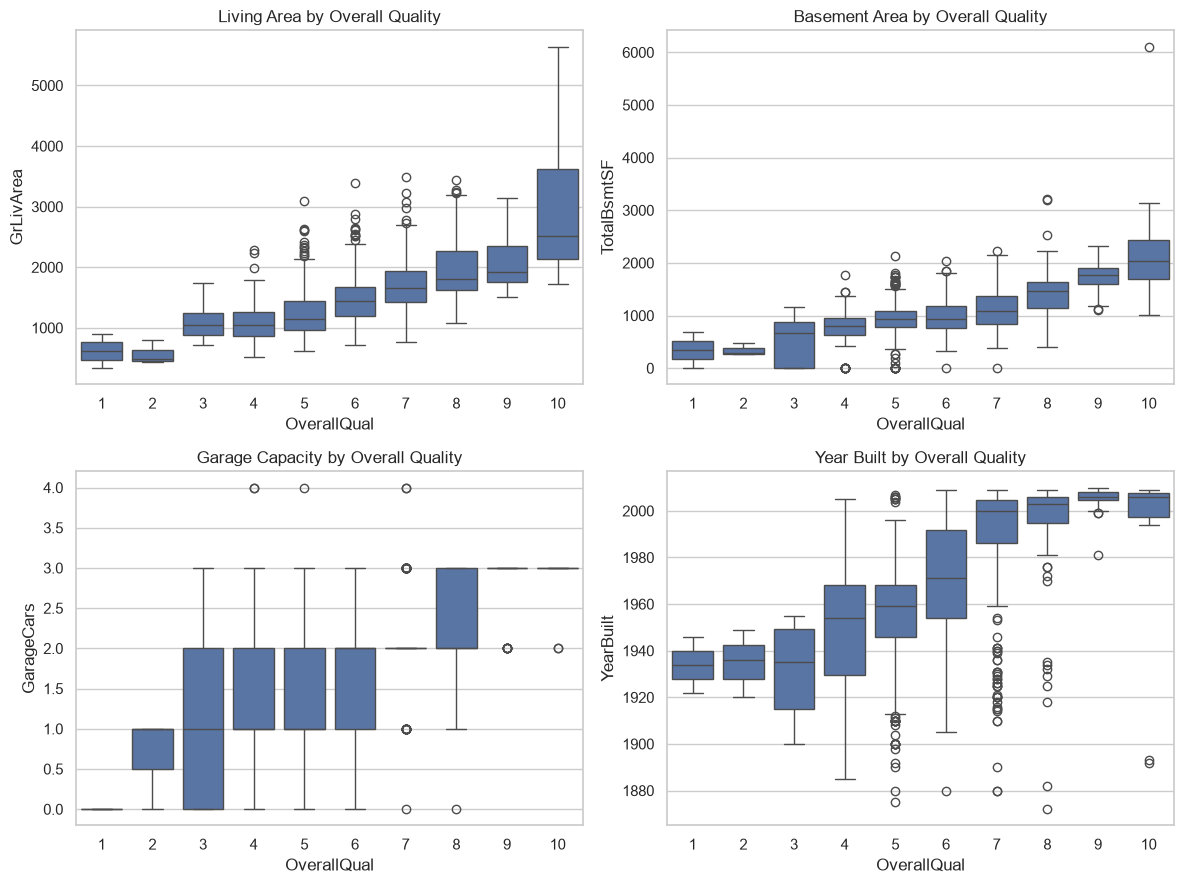

In [27]:
# Select physical characteristics for exploration
features = [
    "GrLivArea",
    "OverallQual",
    "YearBuilt",
    "TotalBsmtSF",
    "GarageCars",
    "LotArea"
]

# Inspect summary statistics
df[features].describe()

# Check missing values
df[features].isnull().sum()

# Plot distributions of physical characteristics
df[features].hist(figsize=(12, 8), bins=30, edgecolor="black")
plt.tight_layout()
plt.show()

# Examine relationships between living area, year built, and quality
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="GrLivArea",
    hue="OverallQual",
    palette="viridis",
    alpha=0.7
)
plt.title("Living Area vs. Year Built by Overall Quality")
plt.xlabel("Year Built")
plt.ylabel("Above-Ground Living Area (sq ft)")
plt.tight_layout()
plt.show()

# Examine relationships among physical characteristics
sns.pairplot(
    df[features].sample(min(500, len(df)), random_state=42),
    diag_kind="hist",
    corner=True
)
plt.show()

# Examine feature correlations
plt.figure(figsize=(9, 7))
sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Correlations Among Physical Characteristics")
plt.tight_layout()
plt.show()

# Compare physical characteristics across overall quality ratings
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.boxplot(data=df, x="OverallQual", y="GrLivArea", ax=axes[0, 0])
axes[0, 0].set_title("Living Area by Overall Quality")

sns.boxplot(data=df, x="OverallQual", y="TotalBsmtSF", ax=axes[0, 1])
axes[0, 1].set_title("Basement Area by Overall Quality")

sns.boxplot(data=df, x="OverallQual", y="GarageCars", ax=axes[1, 0])
axes[1, 0].set_title("Garage Capacity by Overall Quality")

sns.boxplot(data=df, x="OverallQual", y="YearBuilt", ax=axes[1, 1])
axes[1, 1].set_title("Year Built by Overall Quality")

plt.tight_layout()
plt.show()

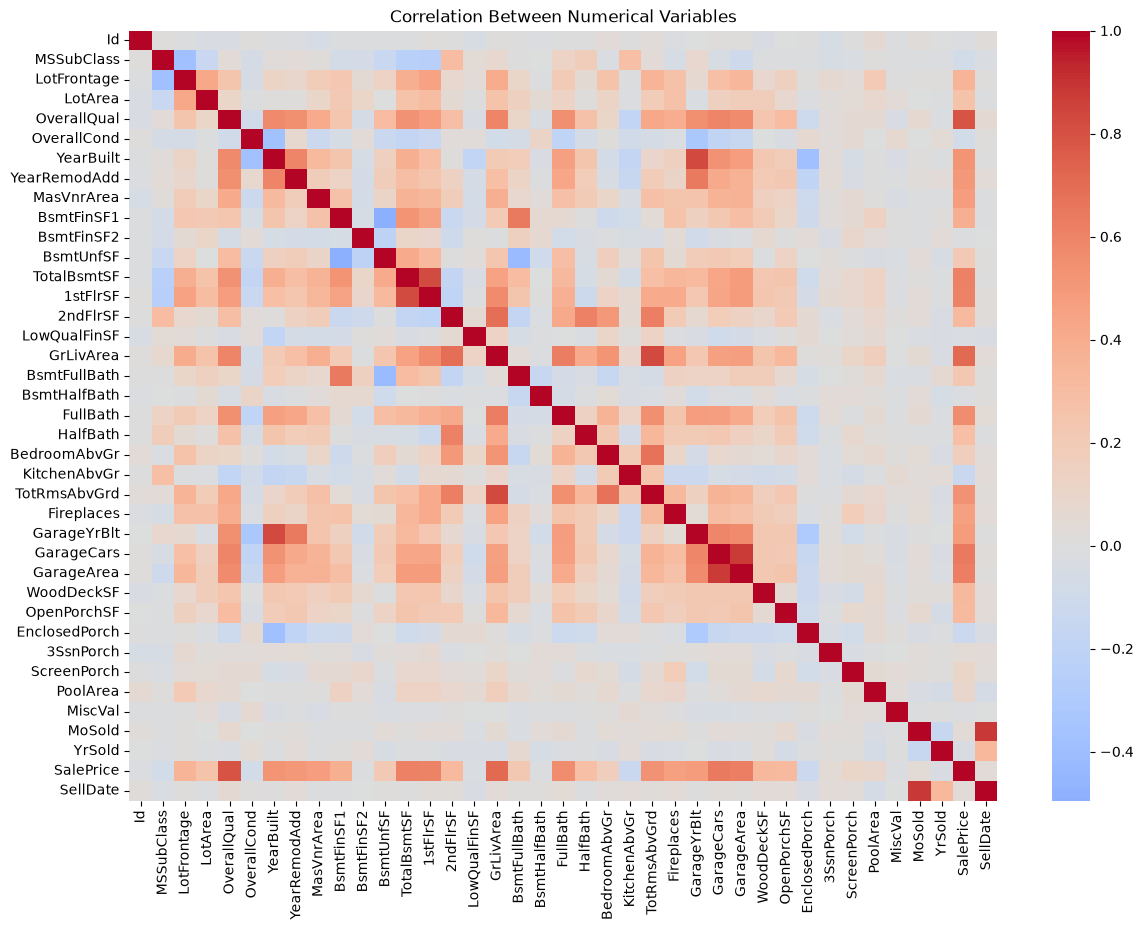

In [19]:
numeric_df = train_data_df.select_dtypes(include='number')

corr = numeric_df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Between Numerical Variables')
plt.show()

## House Age and Renovations

In [20]:
train_data_df['HouseAgeAtSale'] = train_data_df['YrSold'] - train_data_df['YearBuilt']
train_data_df['YearsSinceRemodel'] = train_data_df['YrSold'] - train_data_df['YearRemodAdd']

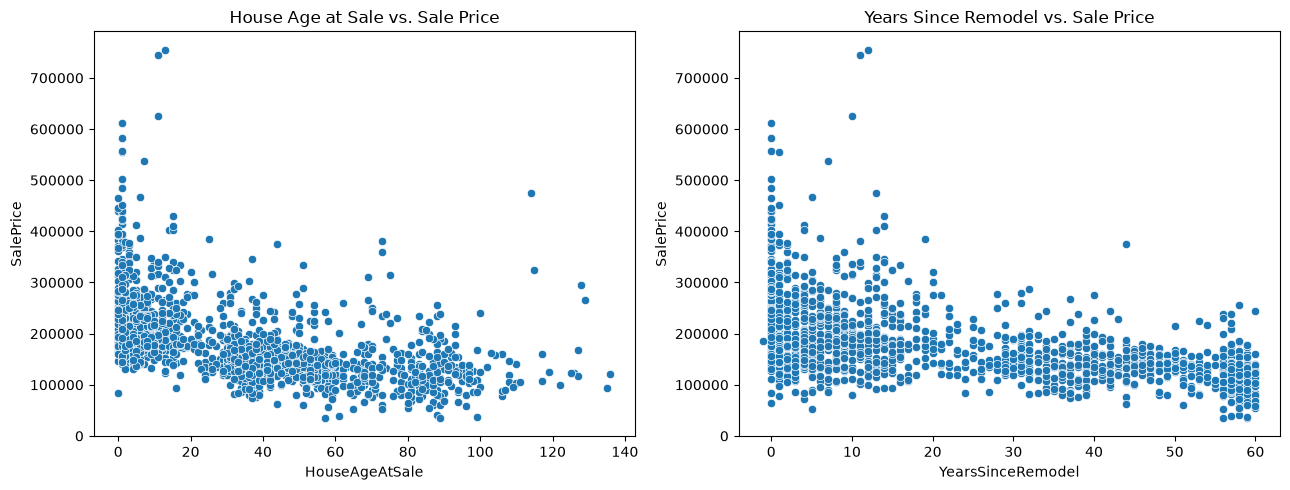

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=train_data_df, x='HouseAgeAtSale', y='SalePrice', ax=axes[0])
axes[0].set_title('House Age at Sale vs. Sale Price')

sns.scatterplot(data=train_data_df, x='YearsSinceRemodel', y='SalePrice', ax=axes[1])
axes[1].set_title('Years Since Remodel vs. Sale Price')

plt.tight_layout()
plt.show()

## Outliers

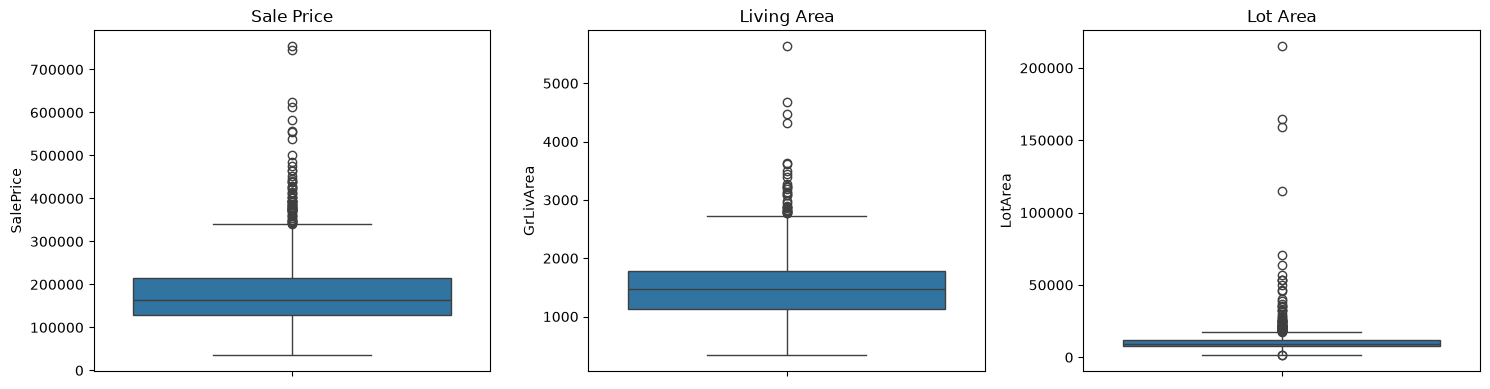

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(y=train_data_df['SalePrice'], ax=axes[0])
sns.boxplot(y=train_data_df['GrLivArea'], ax=axes[1])
sns.boxplot(y=train_data_df['LotArea'], ax=axes[2])

axes[0].set_title('Sale Price')
axes[1].set_title('Living Area')
axes[2].set_title('Lot Area')

plt.tight_layout()
plt.show()

# Question 3

This explores how dwelling configuration, interior systems, basement and garage features, bathroom count, and outdoor amenities vary with sale price. It complements the first EDA, which focused on living area, neighborhood, overall quality, age, and general outliers. Group summaries show sample sizes alongside medians; observed differences are descriptive, not causal.

In [23]:
sns.set_theme(style='whitegrid')
train_data_df = pd.read_csv('../data/train.csv')
print(f'Training rows: {len(train_data_df):,}')
print(f'Columns: {train_data_df.shape[1]}')
train_data_df.head()

Training rows: 1,460
Columns: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Dwelling configuration

Compare sale prices across building types and house styles. Categories with very few sales can have unstable medians, so check the counts before drawing conclusions.

,count,median
BldgType,,
TwnhsE,114,172200.0
1Fam,1220,167900.0
Twnhs,43,137500.0
Duplex,52,135980.0
2fmCon,31,127500.0


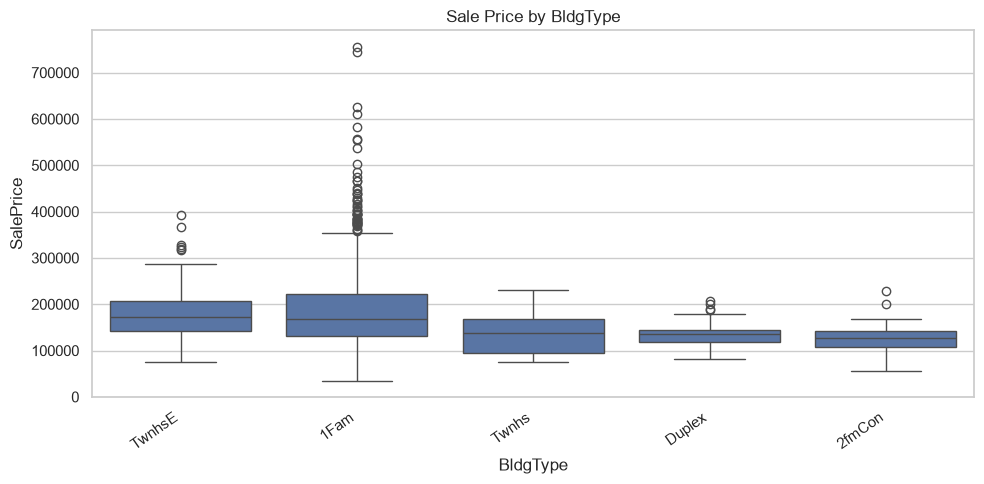

,count,median
HouseStyle,,
2.5Fin,8,194000.0
2Story,445,190000.0
SLvl,65,164500.0
1Story,726,154750.0
SFoyer,37,135960.0
2.5Unf,11,133900.0
1.5Fin,154,132000.0
1.5Unf,14,111250.0


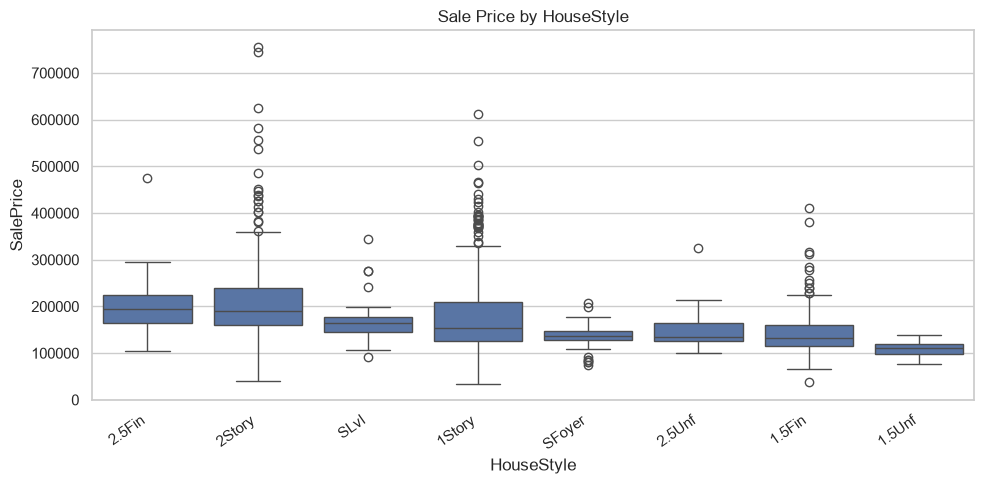

In [24]:
for feature in ['BldgType', 'HouseStyle']:
    summary = (
        train_data_df.groupby(feature, observed=True)['SalePrice']
        .agg(count='size', median='median')
        .sort_values('median', ascending=False)
    )
    display(summary)
    order = summary.index.tolist()
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=train_data_df, x=feature, y='SalePrice', order=order)
    plt.xticks(rotation=35, ha='right')
    plt.title(f'Sale Price by {feature}')
    plt.tight_layout()
    plt.show()

## Interior systems and finish

KitchenQual and HeatingQC are ordered ratings in the data dictionary. Compare their distributions and sale-price summaries without treating the numeric-looking category labels as continuous measurements.

,count,median
KitchenQual,,
Ex,100,316750.0
Fa,39,115000.0
Gd,586,201400.0
TA,735,137000.0


,count,median
HeatingQC,,
Ex,741,194700.0
Fa,49,123500.0
Gd,241,152000.0
Po,1,87000.0
TA,428,135000.0


,count,median
CentralAir,,
N,95,98000.0
Y,1365,168000.0


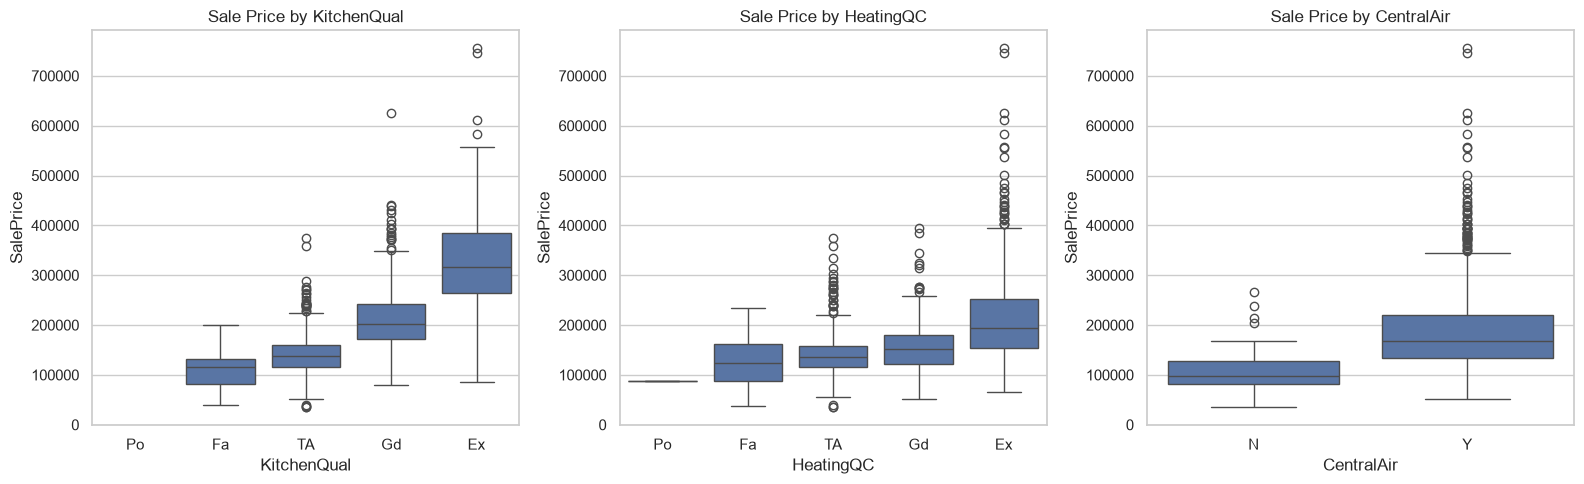

In [25]:
quality_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for axis, feature, order in [
    (axes[0], 'KitchenQual', quality_order),
    (axes[1], 'HeatingQC', quality_order),
    (axes[2], 'CentralAir', ['N', 'Y']),
]:
    summary = train_data_df.groupby(feature, dropna=False, observed=True)['SalePrice'].agg(count='size', median='median')
    display(summary)
    sns.boxplot(data=train_data_df, x=feature, y='SalePrice', order=order, ax=axis)
    axis.set_title(f'Sale Price by {feature}')

plt.tight_layout()
plt.show()

## Basement and garage features

Blank ratings and finish values in these fields indicate that a home may not have that feature. Label missing values as `None` to keep absence in the comparisons.

,count,median
BsmtFinType1,,
None,37,101800.0
Unf,430,161750.0
LwQ,74,139000.0
Rec,133,142000.0
BLQ,148,139100.0
ALQ,220,149250.0
GLQ,418,213750.0


,count,median
GarageFinish,,
None,81,100000.0
Unf,605,135000.0
RFn,422,190000.0
Fin,352,215000.0


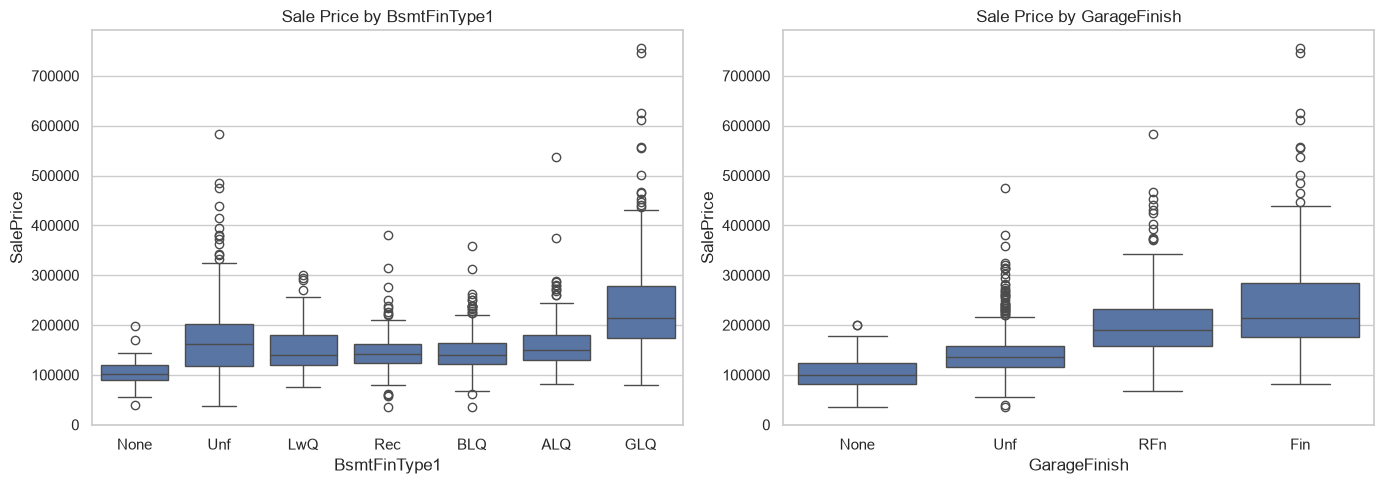

,count,median
TotalBathrooms,,
1.0,228,112250.0
1.5,129,142500.0
2.0,456,145000.0
2.5,295,184000.0
3.0,186,213750.0
3.5,144,247000.0
4.0,13,299800.0
4.5,7,250000.0
5.0,1,145900.0


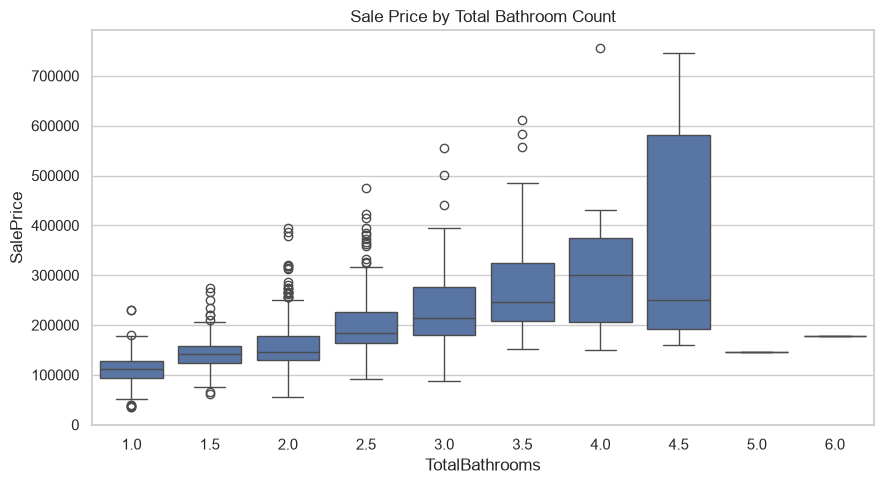

,Feature,Area,Count,MedianSalePrice
0,WoodDeckSF,None,761.0,144152.0
1,WoodDeckSF,Present,699.0,187000.0
2,OpenPorchSF,None,656.0,136700.0
3,OpenPorchSF,Present,804.0,192000.0
4,EnclosedPorch,None,1252.0,170000.0
5,EnclosedPorch,Present,208.0,133350.0
6,3SsnPorch,None,1436.0,162000.0
7,3SsnPorch,Present,24.0,187500.0
8,ScreenPorch,None,1344.0,160000.0
9,ScreenPorch,Present,116.0,175000.0


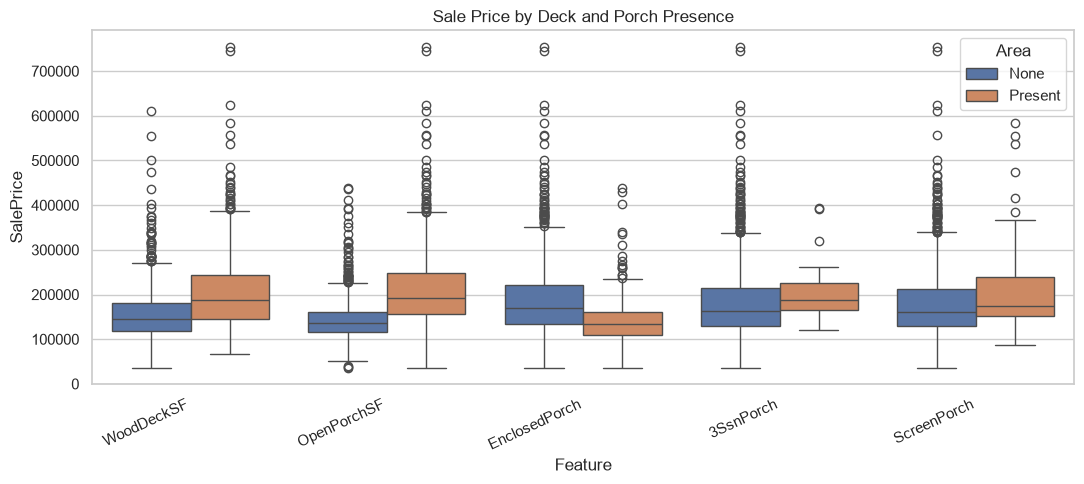

In [26]:
feature_orders = {
    'BsmtFinType1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'GarageFinish': ['None', 'Unf', 'RFn', 'Fin'],
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for axis, (feature, order) in zip(axes, feature_orders.items()):
    plot_data = train_data_df.assign(**{feature: train_data_df[feature].fillna('None')})
    summary = plot_data.groupby(feature, observed=True)['SalePrice'].agg(count='size', median='median').reindex(order)
    display(summary)
    sns.boxplot(data=plot_data, x=feature, y='SalePrice', order=order, ax=axis)
    axis.set_title(f'Sale Price by {feature}')

plt.tight_layout()
plt.show()

train_data_df['TotalBathrooms'] = (
    train_data_df['FullBath']
    + 0.5 * train_data_df['HalfBath']
    + train_data_df['BsmtFullBath']
    + 0.5 * train_data_df['BsmtHalfBath']
)
bath_summary = train_data_df.groupby('TotalBathrooms', observed=True)['SalePrice'].agg(count='size', median='median').sort_index()
display(bath_summary)

plt.figure(figsize=(9, 5))
sns.boxplot(data=train_data_df, x='TotalBathrooms', y='SalePrice')
plt.title('Sale Price by Total Bathroom Count')
plt.tight_layout()
plt.show()

outdoor_features = ['WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']
outdoor_rows = []
for feature in outdoor_features:
    presence = train_data_df[feature].gt(0).map({False: 'None', True: 'Present'})
    grouped = train_data_df.assign(Feature=presence).groupby('Feature', observed=True)['SalePrice'].agg(count='size', median='median')
    for category, values in grouped.iterrows():
        outdoor_rows.append({'Feature': feature, 'Area': category, 'Count': values['count'], 'MedianSalePrice': values['median']})
outdoor_summary = pd.DataFrame(outdoor_rows)
display(outdoor_summary)

plot_data = train_data_df[outdoor_features + ['SalePrice']].melt(id_vars='SalePrice', var_name='Feature', value_name='Area')
plot_data['Area'] = plot_data['Area'].gt(0).map({False: 'None', True: 'Present'})
plt.figure(figsize=(11, 5))
sns.boxplot(data=plot_data, x='Feature', y='SalePrice', hue='Area', hue_order=['None', 'Present'])
plt.xticks(rotation=25, ha='right')
plt.title('Sale Price by Deck and Porch Presence')
plt.tight_layout()
plt.show()